# Supplementary Figure 13

In this notebook, we'll generate figure panels for use in Supplementary Figure 13, which shows CD38 changes across all TEA-seq modalities..

## Load packages

hise: The Human Immune System Explorer R SDK package  
purrr: Functional programming tools  
dplyr: Dataframe handling functions  
ggplot2: plotting functions  
ggrepel: text plotting with repulsion  
cowplot: multi-panel plot assembly

In [1]:
quiet_library <- function(...) { suppressPackageStartupMessages(library(...)) }
quiet_library(hise)
quiet_library(purrr)
quiet_library(dplyr)
quiet_library(ggplot2)
quiet_library(ggrepel)
quiet_library(cowplot)
quiet_library(Seurat)

Warning message:
“package ‘purrr’ was built under R version 4.4.3”
Warning message:
“package ‘dplyr’ was built under R version 4.4.3”
Warning message:
“package ‘ggplot2’ was built under R version 4.4.3”
Warning message:
“package ‘ggrepel’ was built under R version 4.4.3”
Warning message:
“package ‘cowplot’ was built under R version 4.4.3”
Warning message:
“package ‘Seurat’ was built under R version 4.4.3”
Warning message:
“package ‘SeuratObject’ was built under R version 4.4.3”
Warning message:
“package ‘sp’ was built under R version 4.4.3”


In [2]:
out_dir <- "output/supp_figure_13"
if(!dir.exists(out_dir)) { dir.create(out_dir, recursive = TRUE) }

In [3]:
in_uuids <- list()

In [4]:
out_files <- c()

## Retrieve files

Now, we'll use the HISE SDK package to retrieve the Seurat objects and cell type labels based on file UUIDs.

#### Seurat objects for gene expression

In [5]:
so_uuids <- list(
    "7bdac6ef-e5e5-4150-b4f3-9c1a1e250334", # CD4 T cell Seurat object
    "46438bc4-cde6-4ae6-b349-9c513dd9d16f" # CD8 T cell Seurat object
)

In [6]:
so_files <- cacheFiles(so_uuids)

[2026-10-08 14:57:35] INFO  Calling cacheFiles
[1] "downloading fileID 7bdac6ef-e5e5-4150-b4f3-9c1a1e250334"
[1] "downloading fileID 46438bc4-cde6-4ae6-b349-9c513dd9d16f"
[2026-10-08 14:57:43] INFO  Finished cacheFiles successfully (time_elapsed=4.574s)


In [7]:
in_uuids <- c(in_uuids, so_uuids)

#### Cell type labels for Seurat objects

In [8]:
label_uuids <- list(
    "ebd4bee7-2f5d-46e1-b2fc-22157f1b8d04", # CD4 type labels
    "4d6aade9-288c-452f-8f0d-ac59e539f4cc"  # CD8 type labels
)

In [9]:
label_files <- cacheFiles(label_uuids)

[2026-10-08 14:57:43] INFO  Calling cacheFiles
[1] "downloading fileID ebd4bee7-2f5d-46e1-b2fc-22157f1b8d04"
[1] "downloading fileID 4d6aade9-288c-452f-8f0d-ac59e539f4cc"
[2026-10-08 14:57:49] INFO  Finished cacheFiles successfully (time_elapsed=3.389s)


In [10]:
in_uuids <- c(in_uuids, label_uuids)

In [11]:
all_labels <- map_dfr(label_files, read.csv)

#### DEG results

In [12]:
deg_uuid <- list("fc83b89f-fd26-43b8-ac91-29c539703a45")

In [13]:
deg_file <- cacheFiles(deg_uuid)

[2026-10-08 14:57:51] INFO  Calling cacheFiles
[1] "downloading fileID fc83b89f-fd26-43b8-ac91-29c539703a45"
[2026-10-08 14:57:55] INFO  Finished cacheFiles successfully (time_elapsed=1.811s)


In [14]:
in_uuids <- c(in_uuids, deg_uuid)

In [15]:
all_deg <- read.csv(deg_file)

#### DDE results

In [16]:
dde_uuid <- "adbf3c9e-4bf9-4e27-b382-6bd735c6d666"
dde_file <- cacheFiles(list(dde_uuid))

[2026-10-08 14:58:01] INFO  Calling cacheFiles
[1] "downloading fileID adbf3c9e-4bf9-4e27-b382-6bd735c6d666"
[2026-10-08 14:58:06] INFO  Finished cacheFiles successfully (time_elapsed=1.981s)


In [17]:
in_uuids <- c(in_uuids, list(dde_uuid))

In [18]:
all_dde <- read.csv(dde_file)

#### Cell type and treatment metadata for positioning

In [19]:
type_colors <- read.csv("../common/color_sets/aifi_cell_type_colors.csv") %>%
  filter(cell_type_label != "CD8 MAIT")

In [79]:
treat_colors <- read.csv("../common/color_sets/treat_time_colors.csv") %>%
  filter(treat_time != "untreated_0") %>%
  filter(!grepl("dmso", treatment))

## CD38 Dot Plots

In [21]:
all_so <- map(so_files, readRDS)

Normalize ADTs

In [22]:
all_so <- map(
    all_so,
    function(so) {
        DefaultAssay(so) <- "ADT"
        NormalizeData(
            so, 
            normalization.method = "CLR",
            margin = 2
        )
    }
)

Normalizing across cells

Normalizing across cells



Get metadata

In [23]:
so_meta <- map(all_so, "meta.data")

Get CD38 expression

In [24]:
cd38_dfs <- map(
    all_so,
    function(so) {
        cd38_rna <- so@assays$RNA@data["CD38",]
        cd38_adt <- so@assays$ADT@data["CD38",]
        cd38_df <- data.frame(
            barcodes = names(cd38_rna),
            cd38_rna = unname(cd38_rna),
            cd38_adt = unname(cd38_adt)
        )
        return(cd38_df)
    }
)

Put it all together

In [25]:
joint_df <- list_rbind(so_meta) %>%
  left_join(list_rbind(cd38_dfs)) %>%
  left_join(all_labels) %>%
  filter(treatment != "untreated")

Joining with `by = join_by(barcodes)`
Joining with `by = join_by(barcodes, treatment, timepoint)`


In [26]:
mean_nz <- function(x) { mean(x[x != 0]) }
frac_nz <- function(x) { sum(x != 0) / length(x) }

In [27]:
y_order <- data.frame(
    treatment = c("dexamethasone", "bortezomib", "lenalidomide", "dmso"),
    ypos = 1:4
)

In [28]:
plot_df <- joint_df %>%
  group_by(aifi_cell_type, treatment, timepoint) %>%
  summarise(
      mean_nz_cd38_rna = mean_nz(cd38_rna),
        frac_nz_cd38_rna = frac_nz(cd38_rna),
        mean_nz_cd38_adt = mean_nz(cd38_adt),
        frac_nz_cd38_adt = frac_nz(cd38_adt),
      .groups = "keep"
    ) %>%
  left_join(y_order) %>%
  left_join(type_colors)

Joining with `by = join_by(treatment)`
Joining with `by = join_by(aifi_cell_type)`


## Gene expression

In [29]:
head(type_colors)

,aifi_cell_type,cell_type_label,cell_type_color,cell_type_xpos,cell_type_ypos
,<chr>,<chr>,<chr>,<int>,<int>
1,t_cd4_naive,CD4 Naive,#93A7D1,1,7
2,t_cd4_cm,CD4 CM,#00AEEF,2,6
3,t_cd4_em,CD4 EM,#1C75BC,3,5
4,t_cd4_treg,CD4 Treg,#E57A93,4,4
5,t_cd8_naive,CD8 Naive,#8DC63F,5,3
6,t_cd8_memory,CD8 Memory,#009444,6,2


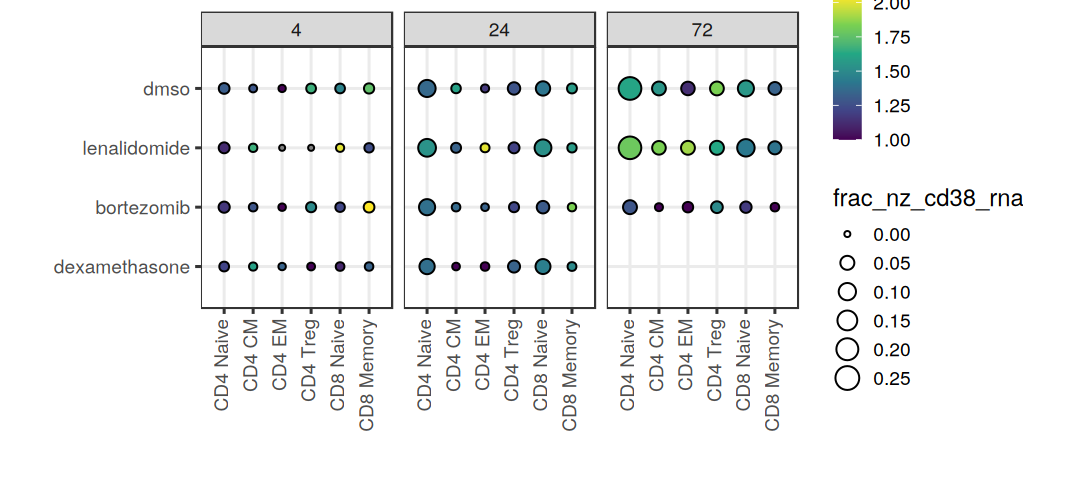

In [30]:
options(repr.plot.width = 9, repr.plot.height = 4)
cd38_rna_dot_plot <- ggplot() +
  geom_point(
      data = plot_df,
      aes(
          x = cell_type_xpos,
          y = ypos,
          fill = mean_nz_cd38_rna,
          size = frac_nz_cd38_rna
      ),
      pch = 21
  ) +
  scale_y_continuous(
      "",
      breaks = y_order$ypos,
      labels = y_order$treatment,
      limits = c(0.5, 4.5)
  ) +
  scale_x_continuous(
      "",
      breaks = type_colors$cell_type_xpos,
      labels = type_colors$cell_type_label,
      limits = c(0.5, 6.5)
  ) +
  scale_size_continuous(
      limits = c(0,0.25)
  ) +
  scale_fill_viridis_c() +
  facet_wrap(
      ~ timepoint,
      ncol = 3
  ) +
  theme_bw(base_size = 14) +
  theme(axis.text.x = element_text(angle = 90, hjust = 1, vjust = 0.3),
        panel.grid.minor = element_blank())
cd38_rna_dot_plot

In [32]:
cd38_rna_dot_file <- file.path(out_dir, paste0("cd38_rna_dot_plot_", Sys.Date(), ".pdf"))

ggsave(
    cd38_rna_dot_file,
    cd38_rna_dot_plot,
    width = 9, height = 4
)

out_files <- c(out_files, cd38_rna_dot_file)

## ADT expression

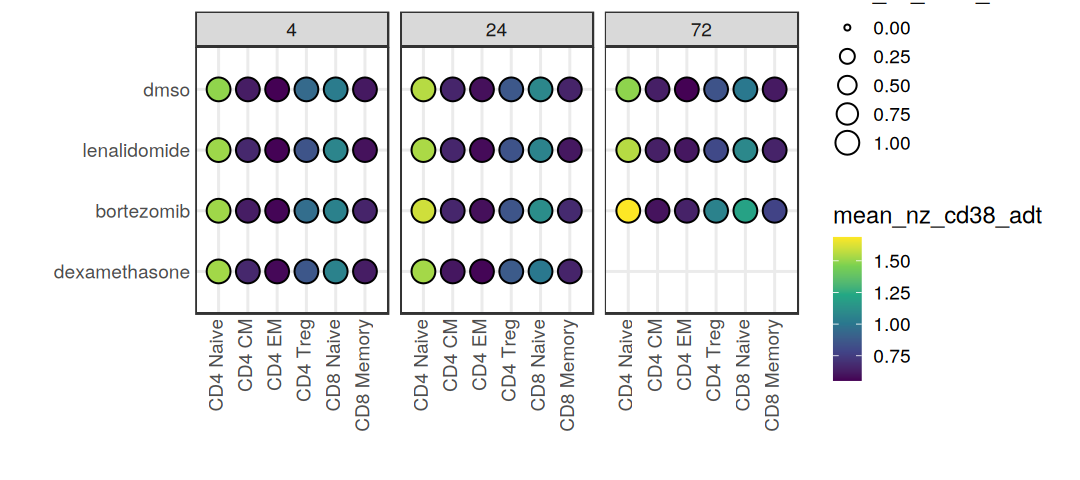

In [33]:
options(repr.plot.width = 9, repr.plot.height = 4)
cd38_adt_dot_plot <- ggplot() +
  geom_point(
      data = plot_df,
      aes(
          x = cell_type_xpos,
          y = ypos,
          fill = mean_nz_cd38_adt,
          size = frac_nz_cd38_adt
      ),
      pch = 21
  ) +
  scale_y_continuous(
      "",
      breaks = y_order$ypos,
      labels = y_order$treatment,
      limits = c(0.5, 4.5)
  ) +
  scale_x_continuous(
      "",
      breaks = type_colors$cell_type_xpos,
      labels = type_colors$cell_type_label,
      limits = c(0.5, 6.5)
  ) +
  scale_size_continuous(
      limits = c(0,1)
  ) +
  scale_fill_viridis_c() +
  facet_wrap(
      ~ timepoint,
      ncol = 3
  ) +
  theme_bw(base_size = 14) +
  theme(axis.text.x = element_text(angle = 90, hjust = 1, vjust = 0.3),
        panel.grid.minor = element_blank(),
        axis.ticks = element_blank())
cd38_adt_dot_plot

In [34]:
cd38_adt_dot_file <- file.path(out_dir, paste0("cd38_adt_dot_plot_", Sys.Date(), ".pdf"))

ggsave(
    cd38_adt_dot_file,
    cd38_adt_dot_plot,
    width = 9, height = 4
)

out_files <- c(out_files, cd38_adt_dot_file)

## CD38 Diff Heatmaps

Heatmap plots for CD38 gene and ADT changes

In [89]:
treat_colors <- treat_colors %>%
  select(treat_time, treat_order) %>%
  mutate(treat_order = ifelse(grepl("len", treat_time), treat_order + 0.5, treat_order),
         treat_order = ifelse(grepl("dex", treat_time), treat_order + 1, treat_order))

In [90]:
target_genes <- c(
    "CD38"
)

### DEG heatmap

In [116]:
plot_deg <- all_deg %>%
  filter(gene %in% target_genes) %>%
  mutate(treat_time = paste0(fg, "_", timepoint)) %>%
  mutate(treatment = fg) %>%
  select(aifi_cell_type, gene, fg, timepoint, treatment, treat_time, logFC, nomP, adjP)

In [117]:
plot_df <- plot_deg %>%
  left_join(treat_colors) %>%
  left_join(type_colors)

Joining with `by = join_by(treat_time)`
Joining with `by = join_by(aifi_cell_type)`


In [118]:
missing_panels <- expand.grid(
    treat_order = unique(treat_colors$treat_order),
    cell_type_ypos = unique(type_colors$cell_type_ypos),
    timepoint = c("4","24","72")
)
missing_panels <- missing_panels %>%
  filter(!paste(treat_order, cell_type_ypos, timepoint) %in% paste(plot_df$treat_order, plot_df$cell_type_ypos, plot_df$timepoint))

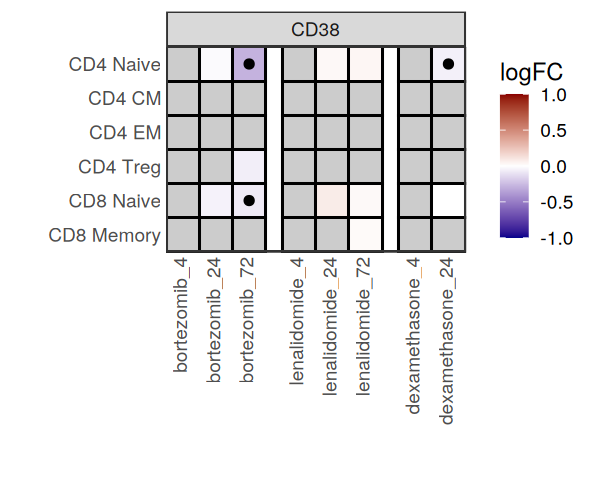

In [119]:
options(repr.plot.width = 5, repr.plot.height = 4)
cd38_rna_diff_plot <- ggplot() +
  geom_rect(
      data = missing_panels,
      aes(
          xmin = treat_order - 0.5,
          xmax = treat_order + 0.5,
          ymin = cell_type_ypos - 0.5,
          ymax = cell_type_ypos + 0.5
      ),
      fill = "gray80",
      color = "black"
  ) +
  geom_rect(
      data = plot_df,
      aes(
          xmin = treat_order - 0.5,
          xmax = treat_order + 0.5,
          ymin = cell_type_ypos - 0.5,
          ymax = cell_type_ypos + 0.5,
          fill = logFC
      ),
      color = "black"
  ) +
  geom_point(
      data = plot_df %>%
        filter(adjP < 0.05),
      aes(
          x = treat_order,
          y = cell_type_ypos
      ),
      color = "black"
  ) +
  scale_y_continuous(
      "",
      breaks = type_colors$cell_type_ypos,
      labels = type_colors$cell_type_label,
      expand = c(0,0)
  ) +
  scale_x_continuous(
      "",
      breaks = treat_colors$treat_order,
      labels = treat_colors$treat_time,
      expand = c(0,0)
  ) +
  scale_fill_gradient2(
      low = "darkblue",
      mid = "white",
      high = "darkred",
      midpoint = 0,
      limits = c(-1, 1)
  ) +
  facet_wrap(
      ~ gene
  ) +
  theme_bw(base_size = 14) +
  theme(axis.text.x = element_text(angle = 90, hjust = 1, vjust = 0.3),
        panel.grid = element_blank(),
        axis.ticks = element_blank())
cd38_rna_diff_plot

In [120]:
cd38_rna_diff_file <- file.path(out_dir, paste0("cd38_rna_diff_plot_", Sys.Date(), ".pdf"))

ggsave(
    cd38_rna_diff_file,
    cd38_rna_diff_plot,
    width = 5, height = 4
)

out_files <- c(out_files, cd38_rna_diff_file)

### DDE heatmap

In [121]:
plot_deg <- all_dde %>%
  filter(feature %in% target_genes) %>%
  mutate(treat_time = paste0(fg, "_", timepoint)) %>%
  mutate(treatment = fg) %>%
  select(aifi_cell_type, feature, fg, timepoint, treatment, treat_time, logFC, nomP, adjP)

In [122]:
plot_df <- plot_deg %>%
  left_join(treat_colors) %>%
  left_join(type_colors)

Joining with `by = join_by(treat_time)`
Joining with `by = join_by(aifi_cell_type)`


In [123]:
missing_panels <- expand.grid(
    treat_order = unique(treat_colors$treat_order),
    cell_type_ypos = unique(type_colors$cell_type_ypos),
    timepoint = c("4","24","72")
)
missing_panels <- missing_panels %>%
  filter(!paste(treat_order, cell_type_ypos, timepoint) %in% paste(plot_df$treat_order, plot_df$cell_type_ypos, plot_df$timepoint))

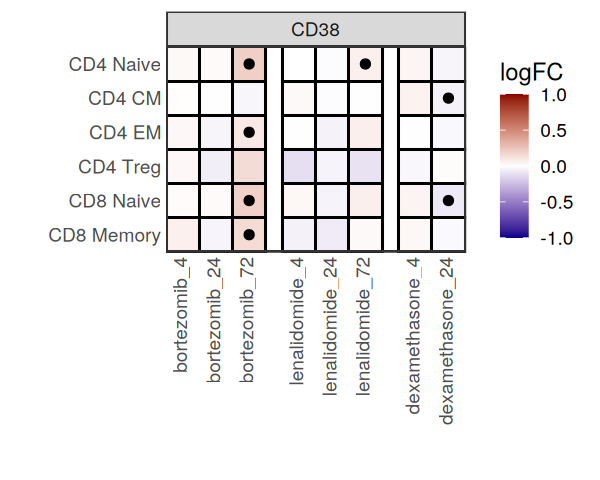

In [126]:
options(repr.plot.width = 5, repr.plot.height = 4)
cd38_adt_diff_plot <- ggplot() +
  geom_rect(
      data = missing_panels,
      aes(
          xmin = treat_order - 0.5,
          xmax = treat_order + 0.5,
          ymin = cell_type_ypos - 0.5,
          ymax = cell_type_ypos + 0.5
      ),
      fill = "gray80",
      color = "black"
  ) +
  geom_rect(
      data = plot_df,
      aes(
          xmin = treat_order - 0.5,
          xmax = treat_order + 0.5,
          ymin = cell_type_ypos - 0.5,
          ymax = cell_type_ypos + 0.5,
          fill = logFC
      ),
      color = "black"
  ) +
  geom_point(
      data = plot_df %>%
        filter(adjP < 0.05),
      aes(
          x = treat_order,
          y = cell_type_ypos
      ),
      color = "black"
  ) +
  scale_y_continuous(
      "",
      breaks = type_colors$cell_type_ypos,
      labels = type_colors$cell_type_label,
      expand = c(0,0)
  ) +
  scale_x_continuous(
      "",
      breaks = treat_colors$treat_order,
      labels = treat_colors$treat_time,
      expand = c(0,0)
  ) +
  scale_fill_gradient2(
      low = "darkblue",
      mid = "white",
      high = "darkred",
      midpoint = 0,
      limits = c(-1, 1)
  ) +
  facet_wrap(
      ~ feature
  ) +
  theme_bw(base_size = 14) +
  theme(axis.text.x = element_text(angle = 90, hjust = 1, vjust = 0.3),
        panel.grid = element_blank(),
        axis.ticks = element_blank())
cd38_rna_diff_plot

In [127]:
cd38_adt_diff_file <- file.path(out_dir, paste0("cd38_adt_diff_plot_", Sys.Date(), ".pdf"))

ggsave(
    cd38_adt_diff_file,
    cd38_adt_diff_plot,
    width = 5, height = 4
)

out_files <- c(out_files, cd38_adt_diff_file)